<div style="text-align: right; float: right; font-size: 14px; color: #555555; line-height: 1.6;">
    <strong>Anîsa DJEDJE</strong><br>
    Licence Double-Diplôme Mathématiques/Informatique (L3)<br>
    <a href="mailto:anisa.djedje@universite-paris-saclay.fr" style="color: #4A90E2; text-decoration: none;">anisa.djedje@universite-paris-saclay.fr</a>
</div>

<div style="clear: both;"></div>


# Partie 1 : Introduction et Contexte - La Rupture Quantique et l'Émergence de LWE

## 1.1 La vulnérabilité des cryptosystèmes actuels (RSA, ECC)
Les cryptosystèmes à clé publique actuels, tels que RSA ou ceux basés sur les courbes elliptiques (ECC), reposent sur des structures algébriques unidimensionnelles (scalaires) au sein de groupes modulaires. La sécurité de ces protocoles s'appuie sur la complexité algorithmique présumée de deux problèmes fondamentaux de la théorie des nombres :
1. **La factorisation d'entiers** : retrouver deux grands nombres premiers $p$ et $q$ cachés derrière leur produit $n = p \times q$.
2. **Le logarithme discret** : étant donnés un générateur $g$ et un élément $h = g^x \pmod q$, retrouver l'exposant secret $x$.

Cependant, en 1994, Peter Shor a démontré qu'un ordinateur quantique peut résoudre ces deux problèmes en temps polynomial $\mathcal{O}(\log^3 N)$, contre un temps sous-exponential pour les meilleurs algorithmes classiques (comme le General Number Field Sieve).

L'algorithme de Shor exploite la Transformée de Fourier Quantique (QFT) pour identifier la période de la fonction d'exponentiation modulaire $f(x) = a^x \bmod N$, ce qui permet de factoriser $N$ efficacement.Quantification de la menace : Pour factoriser une clé RSA-2048, un ordinateur quantique tolérant aux fautes (Fault-Tolerant Quantum Computer) équipé de 4 099 qubits logiques nécessiterait environ 8 heures de calcul (estimation de Roetteler et al., 2017). RSA-2048 perdrait ainsi toute sécurité.

## 1.2 Le paradigme LWE : le passage du  scalaire au vectoriel
Pour contrer cette menace, une rupture de paradigme est nécessaire : abandonner les structures périodiques unidimensionnelles au profit d'espaces vectoriels de grande dimension $n$. C'est l'idée fondamentale introduite par Oded Regev en 2005 avec le problème **LWE (Learning With Errors)**.

L'équation centrale de LWE s'exprime sous la forme d'un système linéaire modulaire perturbé :
$$b = A \cdot s + e \pmod q$$

Où nous définissons :
* $A \in \mathbb{Z}_q^{m \times n}$ : une matrice publique aléatoire, où $n$ est la dimension du secret (paramètre de sécurité) et $m$ le nombre d'équations disponibles.
* $s \in \mathbb{Z}_q^n$ : le vecteur secret.
* $e \in \mathbb{Z}_q^m$ : un vecteur de bruit (ou d'erreur) dont chaque composante est un petit entier échantillonné selon une distribution gaussienne discrète.
* $b \in \mathbb{Z}_q^m$ : le vecteur résultant, rendu public.

## 1.3 L'échec de l'élimination classique (Pivot de Gauss)

Si le système était exact ($b = A \cdot s \pmod q$), l'algorithme du pivot de Gauss retrouverait $s$ en temps polynomial $\mathcal{O}(n^3)$.
Cependant, l'introduction du bruit $e$ fait échouer cette méthode.

Considérons une opération de pivot élémentaire visant à éliminer un coefficient de la matrice $A$ entre une ligne $i$ et une ligne $j$ :
$$L_i \leftarrow L_i - k \cdot L_j \pmod q$$


Où le coefficient multiplicateur vaut $k = (A[i,1] \cdot A[j,1]^{-1}) \bmod q$. La matrice $A$ étant générée aléatoirement, ce multiplicateur $k$ se comporte comme un élément uniforme dans $\mathbb{Z}_q$, pouvant prendre de grandes valeurs de l'ordre de grandeur de $q$ ($k \approx q$).

Ce pivot se répercute obligatoirement sur le vecteur de bruit.

Le nouveau bruit de la ligne $i$ devient :
$$e'_i = (e_i - k \cdot e_j) \bmod q$$


Amplification géométrique du bruit : En raisonnant sur les ordres de grandeur (raisonnement heuristique), avec $\sigma_e$ l'écart-type du bruit ($|e_i|, |e_j| \approx \sigma_e$), le produit avec le pivot $k$ fait exploser la taille du bruit :

$$|e'_i| \approx |e_i| + q \cdot |e_j| \approx \sigma_e + q \cdot \sigma_e$$

Après les $n$ pivots successifs requis pour réduire la matrice, le bruit final accumulé subit une marche aléatoire dont la variance diverge proportionnellement aux dimensions du système :

$$\text{Var}(e_{\text{final}}) \sim n \cdot q^2 \cdot \sigma_e^2$$

Saturation de l'espace modulaire : Si l'on applique nos paramètres de simulation ($n = 2$, $q = 11$, $\sigma_e = 2$) :

$$\text{Var}(e_{\text{final}}) \sim 2 \cdot 11^2 \cdot 2^2 = 2 \cdot 121 \cdot 2^2 = 968 \gg 11^2$$

Dès que la variance du bruit dépasse largement la taille du module $q^2$, le bruit "déborde" et se répartit de manière totalement uniforme sur l'ensemble de l'espace $\mathbb{Z}_{11}$

Le système devient statistiquement indistinguable d'un tirage aléatoire, rendant la reconstruction du secret $s$ impossible pour un attaquant.

C'est ce que nous allons explorer et analyser étape par étape dans ce notebook.

#Partie 2: Les Briques élémentaires de l'échantillonage

Dans le cadre de cette analyse, nous faisons le choix d'implémenter LWE symétrique (à clé secrète); c'est une variante du problème LWE.

Bien que le standard industriel moderne (comme Kyber/ML-KEM) repose sur des structures asymétriques (à clé publique), la version symétrique partage les mêmes fondations mathématiques.

Cela simplifie l'implémentation et permet une analyse numérique des impacts des différentes variables ($\sigma, m, n, q$).

On commence par définir les fonctions élémentaires de cette formule mathématique :

$$b = A \cdot s + e \pmod q$$

##2.1 Echantillonage gaussien discret

On commence par définir de manière pseudo-aléatoire la matrice publique et le vecteur secret.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#Définitions des paramètres globaux du système
n, m, q = 2, 4, 11

#Initialisation du générateur pseudo-aléatoire
rng = np.random.default_rng(42)  # graine fixée : résultats reproductibles
s = rng.integers(0, q, size=n) #vecteur secret de taille n
A = rng.integers(0, q, size=(m, n)) #matrice publique de taille m*n

print(f"La matrice publique : \n {A}", f"\nLe vecteur secret : {s}")

La matrice publique : 
 [[7 4]
 [4 9]
 [0 7]
 [2 1]] 
Le vecteur secret : [0 8]


Puis, intéressons nous au bruit gaussien $e$ .

On définit d'abord la fonction de densité gaussienne continue sur
$\mathbb{R}$ centrée en $0$ avec un paramètre d'échelle $\sigma > 0$ :

$$ \rho_\sigma(x) = \exp(\frac{-\pi x^2}{\sigma^2})$$

Pour adapter cette fonctions aux entiers dans $\mathbb{Z}$, on définit la **distribution gaussienne discrète $D_\mathbb{Z},_\sigma$**.
La probabilité d'échantilloner un entier spécifique $x \in \mathbb{Z}$ est proportionnelle à sa densité continue.

$$\forall x \in \mathbb{Z}, \quad \mathbb{P}[X = x] = \dfrac{\rho_\sigma(x)}{\sum_{k=-\infty}^{+\infty} \rho_\sigma(k)}$$

**Attention : $\sigma$ n'est pas l'écart-type.** Avec cette convention (celle de la littérature sur les réseaux), $\sigma$ est un *paramètre de largeur*. En identifiant $\rho_\sigma(x) = \exp\left(-\frac{x^2}{2\sigma_e^2}\right)$, on obtient l'écart-type réel du bruit :

$$\sigma_e = \frac{\sigma}{\sqrt{2\pi}} \approx 0{,}4\,\sigma$$

Par exemple, $\sigma = 2$ donne un écart-type d'environ $0{,}8$. Nous le vérifions numériquement ci-dessous.

L'implémentation informatique d'une somme infinie étant impossible, nous tronquons la distribution à l'intervalle $[-6\sigma, 6\sigma]$ (avec au minimum $[-10, 10]$). La probabilité au-delà de cette borne est de l'ordre de $e^{-36\pi} \approx 10^{-49}$ : l'erreur d'approximation est négligeable. La borne s'adapte à $\sigma$, ce qui évite de « couper » artificiellement le bruit quand $\sigma$ devient grand.

In [3]:
def rho_sigma(sigma, x):
  return np.exp((-np.pi*x**2)/sigma**2)

In [4]:
def gaussienne_discrete(sigma, size):
  borne = max(10, int(np.ceil(6 * sigma)))  # troncature à ±6σ : la masse au-delà est négligeable
  values = np.arange(-borne, borne + 1)
  rho_tab = rho_sigma(sigma, values)

  total_rho = np.sum(rho_tab)
  probabilities = rho_tab/total_rho #P[X]

  e = rng.choice(values, size=size, p=probabilities) #choix parmis les valeurs avec proba p

  return e

Nous allons vérifier que la gaussienne discrète forme une "cloche" bien conforme à la théorie.

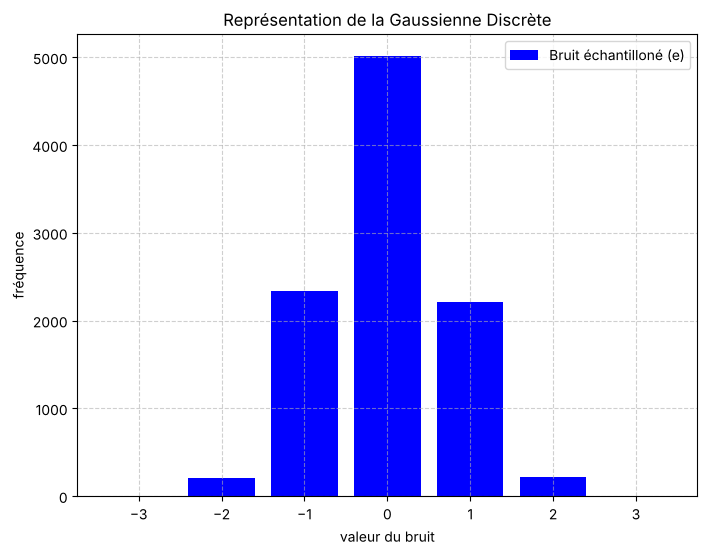

Écart-type mesuré : 0.794  (théorique : σ/√(2π) = 0.798)


In [5]:
sigma = 2.0
bruit = gaussienne_discrete(sigma, size=10000)
x, y = np.unique(bruit, return_counts=True)

plt.figure(figsize=(8, 6))
plt.bar(x, y, color="blue", label="Bruit échantilloné (e)")

plt.title("Représentation de la Gaussienne Discrète")
plt.xlabel("valeur du bruit")
plt.ylabel("fréquence")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

print(f"Écart-type mesuré : {bruit.std():.3f}  (théorique : σ/√(2π) = {sigma/np.sqrt(2*np.pi):.3f})")


**Analyse critique de l'échantillonage** : l'écart-type mesuré correspond bien à la valeur théorique $\sigma/\sqrt{2\pi}$.

Dans nos simulations, nous utilisons parfois un très petit modulo ($q = 11$). On remarque alors un phénomène de **repliement** : si le bruit généré vaut par exemple $-10$, l'application du modulo donne $-10 \equiv 1 \pmod{11}$. Un bruit censé être grand est donc vu par le système comme un bruit faible (ou inversement).

C'est précisément ce repliement qui fera échouer le déchiffrement lorsque $\sigma$ devient trop grand devant $q$ (Partie 4). Pour une implémentation réelle (comme Kyber), le bruit est choisi très petit par rapport à $q$ pour rendre ce phénomène pratiquement impossible.

##2.2 Génération de la paire de clés


Maintenant que nous disposons de la matrice publique $A$, du secret $s$ et de notre générateur de bruit gaussien discret, nous pouvons assembler notre instance LWE. L'objectif est de calculer le vecteur public $b \in \mathbb{Z}_q^m$ défini par la relation :
$$b = A \cdot s + e \pmod q$$

Sous forme matricielle, le système se représente ainsi :$$\begin{pmatrix} b_1 \\ b_2 \\ \vdots \\ b_m \end{pmatrix}
=
\begin{pmatrix}
a_{11} & a_{12} & \cdots & a_{1n} \\
a_{21} & a_{22} & \cdots & a_{2n} \\
\vdots & \vdots & \ddots & \vdots \\
a_{m1} & a_{m2} & \cdots & a_{mn}
\end{pmatrix}
\cdot
\begin{pmatrix} s_1 \\ s_2 \\ \vdots \\ s_n \end{pmatrix}
+
\begin{pmatrix} e_1 \\ e_2 \\ \vdots \\ e_m \end{pmatrix} \pmod q$$


In [6]:
def keygen(sigma, A, s, m, q):
  e = gaussienne_discrete(sigma, m) #on veut un vecteur avec 4 lignes

  produit_matriciel = A @ s

  b = (produit_matriciel + e)%q
  return b


In [7]:
sigma = 2.0
n, m, q = 2, 4, 11
A = rng.integers(0, q, size=(m, n))
s = rng.integers(0, q, size=n)

b = keygen(sigma, A, s, m, q)

print("---VERIFICATION DU PROBLEME LWE---")
print(f"Matrice A (m x n) :\n{A}\n")
print(f"Vecteur secret s (n) : {s}\n")
print(f"Résultat public b (m) : {b}")

---VERIFICATION DU PROBLEME LWE---
Matrice A (m x n) :
[[ 4  1]
 [ 4  4]
 [ 2 10]
 [ 3  1]]

Vecteur secret s (n) : [6 3]

Résultat public b (m) : [5 3 8 9]


Dans notre implémentation de test avec $n=2$ et $q=11$, l'espace des secrets possibles est extrêmement réduit. Un attaquant interceptant $A$ et $b$ n'aurait qu'à tester $q^n = 11^2 = 121$ vecteurs pour retrouver notre secret $s$ par recherche exhaustive.

Dans les applications réelles de la cryptographie post-quantique (comme le standard ML-KEM), les paramètres sont radicalement augmentés : la dimension effective du secret est de $512$ à $1024$, avec un module $q = 3329$.

## Force brute et sécurité réelle

Calculons $q^n$ pour différentes instances :

| Instance | Dimension $n$ | $q$ | Force brute : $q^n$ |
|----------|---|---|-----|
| Nos tests | 2 | 11 | $121$ |
| Kyber-512 (ML-KEM-512) | 512 | 3329 | $\approx 10^{1804}$ |

**Attention : la force brute ne mesure pas la sécurité réelle.** Elle ne donne qu'une borne supérieure du coût d'une attaque. Les meilleures attaques connues contre LWE n'énumèrent pas les secrets : elles utilisent la **réduction de réseaux** (algorithmes LLL et BKZ), bien plus efficaces.

Pour Kyber-512, la sécurité estimée face à ces attaques est d'environ $2^{118}$ opérations (soit $\approx 10^{35}$), très loin des $10^{1804}$ de la force brute. Cela reste hors de portée de tout ordinateur, classique ou quantique, mais c'est **cette** estimation qui sert à choisir les paramètres.

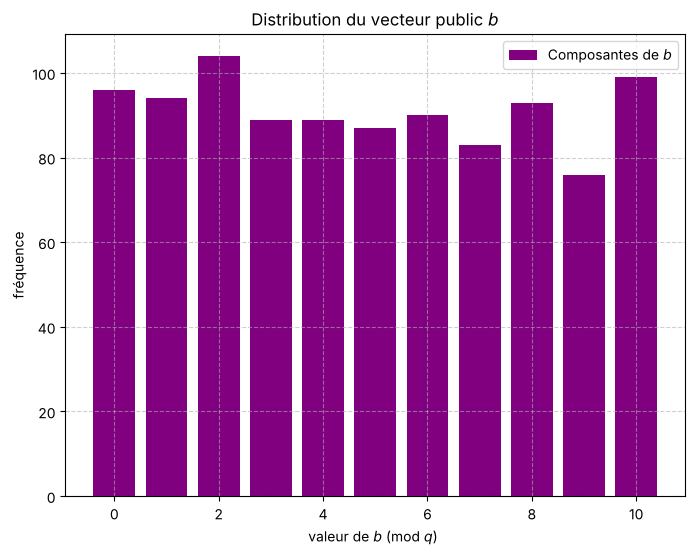

In [8]:
m_test = 1000 # on génère un grand nombre d'équations
A_test = rng.integers(0, q, size=(m_test, n))
e_test = gaussienne_discrete(sigma, m_test)

b_test = keygen(sigma, A_test, s, m_test, q)

# compte les valeurs de chaque occurences entre 0 et 10
valeurs, comptes = np.unique(b_test, return_counts=True)

plt.figure(figsize=(8, 6))
plt.bar(valeurs, comptes, color="purple", label="Composantes de $b$")

plt.title("Distribution du vecteur public $b$")
plt.xlabel("valeur de $b$ (mod $q$) ")
plt.ylabel("fréquence")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

**Observation** :

Alors que le bruit isolé $e$ suivait une distribution en cloche très marquée (Gaussienne discrète), le vecteur public résultant $b$ présente une distribution quasiment plate (**uniforme**) entre 0 et 10.

L'opération de multiplication matricielle combinée au reste modulaire (mod $q$) a totalement masqué la structure de la gaussienne.

**Qu'est-ce que cela signifie ?**

Pour un attaquant qui n'observe que le vecteur $b$, les données ressemblent à un bruit aléatoire uniforme parfait.

Il est impossible de deviner visuellement le secret $s$ ou le bruit initial à partir de ce seul graphique.
Cela **illustre** l'idée de la sécurité de LWE : les échantillons $(A, b)$ sont conçus pour être indistinguables de données uniformes. Attention, ce graphique n'est pas une preuve : avec $n = 2$, le secret se retrouve en 121 essais.

##2.3 Chiffrement

###Le principe du chiffrement d'un bit

Pour envoyer un message secret $ m \in \{0, 1\}$ (un simple bit), l'émetteur ne transmet pas juste $b = A \cdot s + e$ . Il va encoder son bit directement dans le vecteur $b$.

Pour cela, on sépare généralement le système en deux parties. Pour faire simple, imaginons qu'on ajoute le message au format "géant" dans notre équation :
- Pour envoyer un 0, on n'ajoute rien.
- Pour envoyer un 1, on ajoute une valeur très grande, généralement la moitié de $q$ (soit $\lfloor q/2 \rfloor$)

l'équation finale intercepté par l'attaquant est:

$$b = A \cdot s + e + m \cdot \lfloor q/2 \rfloor \pmod q$$

In [9]:
def chiffrer_LWE(msg, sigma, A, s, m, q):
  e = gaussienne_discrete(sigma, m)
  produit_matriciel = A @ s

  # On ajoute l'encodage du message (0 ou q//2) avant le modulo
  b = (produit_matriciel + e + msg * (q // 2)) % q
  return b

##2.4 Déchiffrement


### 2.4.1 L'avantage de l'utilisateur légitime

L'attaquant ne connaît ni $s$ ni $e$. Pour lui, comme on l'a vu sur le graphique plus haut, $b$ ressemble à du bruit uniforme.

Mais l'utilisateur légitime, lui, connaît la clé secrète $s$. Il va donc pouvoir calculer la différence entre ce qu'il reçoit ($b$) et ce que le secret aurait dû donner ($A \cdot s$).

Regardons ce qu'il se passe mathématiquement si l'utilisateur calcule $b - A \cdot s$ (mod $q$):
$$b - A \cdot s \equiv (A \cdot s + e + m \cdot \lfloor q/2 \rfloor) - A \cdot s \pmod q$$
$$ \equiv e + m \cdot \lfloor q/2 \rfloor \pmod q $$

Le terme $A \cdot s$ s'annule parfaitement. Il  ne reste plus que **le bruit** $e$ et **le message**.

### 2.4.2 Le seuillage

Maintenant, l'utilisateur se retrouve avec le vecteur $v = e + m \cdot \lfloor q/2 \rfloor$ (mod $q$). Comment sait-il si le bit d'origine était un 0 ou un 1 ?

C'est là que la taille du bruit devient cruciale:
- Si le message était 0 : l'utilisateur obtient juste $v = e$. Comme le bruit $e$ est très petit (proche de 0), la valeur de $v$ sera très proche de $0$ (ou proche de $q$ à cause du modulo).
- Si le message était 1 : l'utilisateur obtient $v = e + \lfloor q/2 \rfloor$. La valeur sera donc très proche du milieu (autour de $q/2$).

Il suffit alors de regarder où se situent les valeurs : si elles sont proches de 0 ou de $q/2$.

**Attention au modulo :** un bruit négatif « boucle » de l'autre côté. Par exemple, $e = -1$ donne $v = q - 1$, une valeur proche de $q$ et non de $0$. On **recentre** donc chaque composante dans $\left]-q/2,\, q/2\right]$ avant de mesurer sa distance à $0$ :

- si la distance moyenne $\frac{1}{m}\sum_i |v_i|$ est inférieure à $q/4$, le message est $0$ ;
- sinon, le message est $1$.

In [10]:
def dechiffrer_LWE(b, A, s, q):
  v = (b - A @ s) % q

  # Recentrage dans ]-q/2, q/2] : un bruit négatif (ex. -1 ≡ q-1) redevient proche de 0
  v_centre = np.where(v > q // 2, v - q, v)

  # Distance moyenne à 0 : petite si msg = 0, proche de q/2 si msg = 1
  distance_moyenne = np.mean(np.abs(v_centre))

  if distance_moyenne > q / 4:
    return v_centre, 1
  else:
    return v_centre, 0


##2.5 Pourquoi ça fonctionne ? pivot vs calcul direct

La sécurité et la viabilité du cryptosystème LWE reposent sur une asymétrie fondamentale dans la manipulation du bruit.

Nous pouvons résumer cette asymétrie en opposant la situation d'un attaquant passif à celle de l'utilisateur légitime.

###2.5.1 Le point de vue de l'attaquant (Approche par Pivot)

Comme démontré en Section 1.3, un attaquant ne possède pas le secret $s$.
Pour tenter de résoudre le système linéaire $b = A \cdot s + e \pmod q$, sa seule option algébrique classique est de tenter une élimination de Gauss.
Chaque élimination force des combinaisons de lignes qui multiplient le bruit par des coefficients $k \approx q$. Le bruit accumulé subit une marche aléatoire dont la variance diverge :

$$\text{Var}(e_{\text{attaquant}}) \sim n \cdot q^2 \cdot \sigma_e^2 \qquad \text{où } \sigma_e = \frac{\sigma}{\sqrt{2\pi}} \text{ est l'écart-type du bruit}$$

Pour nos paramètres ($n = 2$, $q = 101$, $\sigma = 2$, donc $\sigma_e \approx 0{,}8$), cette variance atteint environ $2 \times 101^2 \times 0{,}64 \approx 13\ 000 > q^2 = 10\ 201$, ce qui sature l'espace modulaire $\mathbb{Z}_q$ (ordre de grandeur heuristique).

L'information utile est définitivement noyée dans un bruit uniforme. L'élimination gaussienne est un échec mathématique.

###2.5.2 Le point de vue de l'utilisateur légitime (Calcul Direct)

À l'inverse, le destinataire légitime possède la clé secrète $s$.

Pour déchiffrer, il n'a jamais besoin de manipuler la matrice $A$ ni de faire de pivots de lignes.Il effectue une simple soustraction vectorielle directe (calcul linéaire) pour isoler le bruit :

$$e = b - A \cdot s \pmod q$$Calculons la variance du bruit manipulé par l'utilisateur légitime :$$\text{Var}(e_{\text{légitime}}) = \sigma_e^2 = \frac{\sigma^2}{2\pi}$$

Pour nos paramètres ($n = 2$, $q = 101$, $\sigma = 2$) :$$\text{Var}(e_{\text{légitime}}) = \frac{2^2}{2\pi} \approx 0{,}64$$

###2.5.3 Synthèse : L'asymétrie de l'information

Pour mesurer le fossé qui sépare l'attaquant de l'utilisateur légitime, nous pouvons calculer le ratio de leurs variances dans notre simulation :

$$\frac{\text{Var}(e_{\text{attaquant}})}{\text{Var}(e_{\text{légitime}})} = \frac{n \cdot q^2 \cdot \sigma_e^2}{\sigma_e^2} = n \cdot q^2$$

Avec nos valeurs ($n=2, q=101$) :

$$2 \times 101^2 = 20\ 402$$

**Conclusion géométrique :** Le bruit auquel fait face l'attaquant est 20 402 fois plus dispersé que celui manipulé par l'utilisateur légitime.

# Partie 3: Validation expérimentale

Avant de lancer des validations sur de grands échantillons, nous testons le comportement de notre chaîne de chiffrement/déchiffrement sur une instance isolée pour un message unitaire ($msg = 1$).

In [11]:
msg = 1

s = rng.integers(0, q, size=n)
A = rng.integers(0, q, size=(m, n))


b = chiffrer_LWE(msg, sigma, A, s, m, q)
v, res = dechiffrer_LWE(b, A, s, q)

print(f"b (vecteur chiffré) est donné par : {b}")
print(f"Le vecteur de déchiffrement v est : {v}")
print(f"Le message décodé est : {res}")

b (vecteur chiffré) est donné par : [ 1  2  3 10]
Le vecteur de déchiffrement v est : [ 4 -5  5  5]
Le message décodé est : 1


Puis on test sur 100 messages.

In [12]:
n, m, q, sigma, nb_msg = 2, 4, 101, 1.0, 100

#On génère la paire de clés
A = rng.integers(0, q, size=(m, n))
s = rng.integers(0, q, size=n)
b = keygen(sigma, A, s, m, q)

succes = 0

for i in range(nb_msg):
  #on génère un bit aléatoire (0 ou 1)
  message_original = int(rng.integers(0, 2))

  #Chiffrement et déchiffrement
  cle_chiffree = chiffrer_LWE(message_original, sigma, A, s, m, q)
  v, message_dechiffre = dechiffrer_LWE(cle_chiffree, A, s, q)

  if message_original == message_dechiffre:
    succes += 1

taux_succes = succes/nb_msg

print("BILAN DE LA VALIDATION LWE")
print(f"Messages testés : {nb_msg}")
print(f"Déchiffrements corrects : {succes}/{nb_msg}")
print(f"Taux de succès global : {taux_succes * 100:.1f} %")

BILAN DE LA VALIDATION LWE
Messages testés : 100
Déchiffrements corrects : 100/100
Taux de succès global : 100.0 %


Les 100 messages sont correctement déchiffrés. C'est cohérent avec la théorie : dans $\mathbb{Z}_{101}$, la borne de décision est

$$\text{Seuil} = q/4 \approx 25$$

alors qu'avec $\sigma = 1$, l'écart-type du bruit n'est que de $\sigma_e = 1/\sqrt{2\pi} \approx 0{,}4$. Les erreurs valent presque toujours $0$ ou $\pm 1$, très loin du seuil : aucun échec de déchiffrement n'est attendu.

Les échecs n'apparaissent que lorsque le bruit devient comparable à $q/4$. C'est ce que nous étudions dans la partie suivante.

# Partie 4 : Analyse paramétrique et transition de phase

##4.1 Méthodologie



Désormais, faisons une étude plus approfondie et plus précise de la valeur de $\sigma$. On cherche à savoir : *Jusqu'à quel niveau de bruit notre système reste-t-il capable de déchiffrer correctement à 100% et à partir de quel moment le bruit devient-il si fort qu'il commence à corrompre les messages ?*

C'est exactement ce qu'on appelle la **transition de phase**.

In [13]:
def etude_transition_phase(n, m, q, sigmas, nb_essais=200):
  taux_tab = []

  for sigma in sigmas :
    success = 0 #nombre de déchiffrements corrects sur nb_essais
    for i in range(nb_essais):
      A = rng.integers(0, q, size=(m, n))
      s = rng.integers(0, q, size=n)

      msg = rng.integers(0, 2)

      b = chiffrer_LWE(msg, sigma, A, s, m, q)

      v, m_dechiffre = dechiffrer_LWE(b, A, s, q)

      if msg == m_dechiffre :
        success += 1
    taux = (success/nb_essais)*100
    taux_tab.append(taux)
  return taux_tab


##4.2 Impact de $\sigma$ (transition de phase)

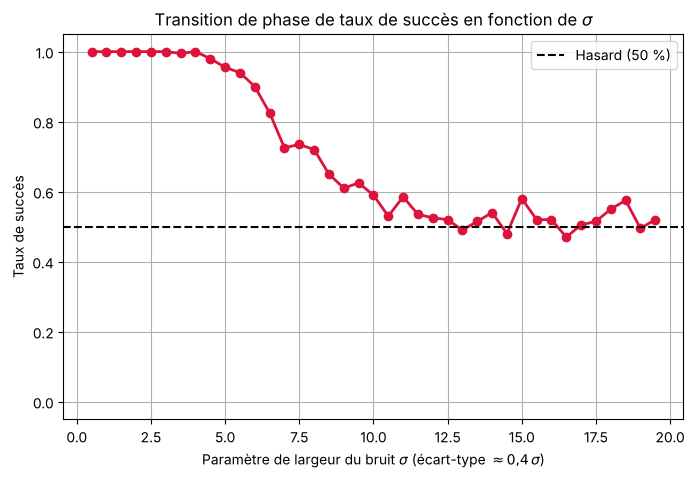

In [14]:
n, m, q = 2, 4, 11
sigmas = np.arange(0.5, 20.0, 0.5)
taux_succes = etude_transition_phase(n, m, q, sigmas)

#on normalise
taux_succes_normalise = np.array(taux_succes)/100.0

plt.figure(figsize=(8, 5))
plt.plot(sigmas, taux_succes_normalise, marker='o', linestyle='-', color="crimson", linewidth=2)

plt.axhline(y=0.5, color="black", linestyle="--", label="Hasard (50 %)")

plt.title(r"Transition de phase de taux de succès en fonction de $\sigma$")
plt.xlabel(r"Paramètre de largeur du bruit $\sigma$ (écart-type $\approx 0{,}4\,\sigma$)")
plt.ylabel("Taux de succès")
plt.ylim(-0.05, 1.05)
plt.grid(True)
plt.legend()
plt.show()



**Observation :** avec $n = 2$, $m = 4$ et $q = 11$, le taux de succès reste à 100 % jusqu'à $\sigma \approx 4$ (écart-type $\approx 1{,}6$), puis décroît progressivement pour atteindre le niveau du hasard (50 %) vers $\sigma \approx 13$.

**Interprétation :** pour $q = 11$, une composante est mal interprétée dès que $|e_i| > q/4 = 2{,}75$, c'est-à-dire $|e_i| \ge 3$.

- Tant que l'écart-type du bruit est petit devant ce seuil, ces erreurs sont rares et la moyenne sur les $m = 4$ composantes reste du bon côté : le déchiffrement est parfait.
- Quand $\sigma$ augmente, les grandes erreurs deviennent fréquentes et certaines « replient » de l'autre côté du modulo : le taux de succès chute.
- Quand l'écart-type devient de l'ordre de $q$, le bruit est pratiquement **uniforme** sur $\mathbb{Z}_{11}$. Le message est alors complètement noyé et le déchiffrement revient à tirer à pile ou face (50 %).

On constate aussi que si $\sigma = 0$, le système se résout instantanément par un pivot de Gauss classique. Introduire un bruit $\sigma > 0$ est donc indispensable pour masquer le secret et bloquer les attaques algébriques.

**Pour résumer,** $\sigma$ doit être assez grand pour assurer la sécurité, mais petit devant $q$ pour garantir la fiabilité du déchiffrement.

##4.3 Impact de m (nombre d'équations)


Comme introduit, $m$ est le nombre d'équations (ou le nombre de lignes de la matrice $A$). C'est le nombre d'indices ou de "morceaux d'information" chiffrés que l'on donne à l'utilisateur pour un seul message.

L'objectif est de tester la résistance du chiffrement face au bruit ($\sigma$) en faisant varier le nombre d'équations $m$. Nous conservons $n = 2$ la taille du secret et $q = 11$ le modulo.

Ce à quoi on s'attend :

- si $m$ est petit (ex: $m$ = 1 ou 2) : on a qu'une ou deux lignes pour calculer la moyenne. De ce fait, si le bruit généré par la gaussienne est un peu fort sur une ligne, la moyenne risque de complètement fausser le résultat.
- si $m$ est plus grand (ex: 20 ou 50) : on a  beaucoup plus de lignes. Et grâce aux statistiques, et plus précisément à **la loi les grands nombres**, les bruits positifs et négatifs vont se compenser et s'annuler lors du calcul de la moyenne. C'est là que le déchiffrement devient robuste.


Commençons par tester 3 valeurs de $m$, $m=2, m=10, m=100$ et de représenter graphiquement l'impact du changement de $m$.

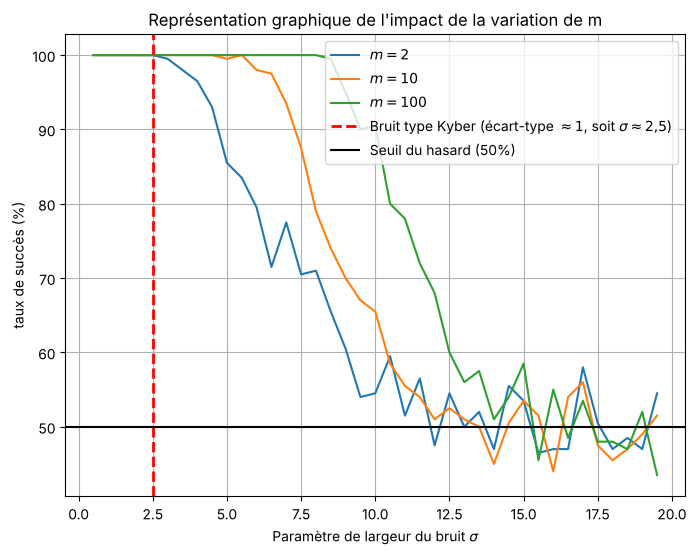

In [15]:
n, q = 2, 11
liste_m = [2, 10, 100]
x = np.arange(0.5, 20.0, 0.5) #les valeurs de sigma

plt.figure(figsize=(8, 6))

for m in liste_m:
  plt.plot(x, etude_transition_phase(n, m, q, x), label=f"$m={m}$")

plt.axvline(x=2.5, color='red', linestyle='--', linewidth=2, label=r'Bruit type Kyber (écart-type $\approx 1$, soit $\sigma \approx 2{,}5$)')
plt.axhline(y=50, color='black', label='Seuil du hasard (50%)')

plt.legend()
plt.xlabel(r"Paramètre de largeur du bruit $\sigma$")
plt.ylabel(r"taux de succès (%)")
plt.grid(True)
plt.title("Représentation graphique de l'impact de la variation de m")
plt.show()




### Résultats et Interprétation

**Observation empirique** : on constate que $m$ décale et durcit la transition de phase :

- Pour $m = 2$, le taux de succès quitte les 100 % dès $\sigma \approx 3$ et décroît lentement.
- Pour $m = 10$, il reste à 100 % jusqu'à $\sigma \approx 6$.
- Pour $m = 100$, il reste à 100 % jusqu'à $\sigma \approx 8$, puis chute de manière beaucoup plus brutale.
- Dans les trois cas, le taux atteint le plancher de 50 % vers $\sigma \approx 12$ à $13$.

**Analyse et Démonstration Mathématique:**
L'utilisateur légitime calcule le vecteur résiduel recentré :

$$v_i = b_i - A_i \cdot s \equiv e_i + msg \cdot \lfloor q/2 \rfloor \pmod q$$

puis la **distance moyenne** $\bar{D} = \frac{1}{m}\sum_{i=1}^m |v_i|$, qu'il compare au seuil $q/4$.

Les termes $|v_i|$ sont indépendants et de même loi. Par la **loi des grands nombres**, $\bar{D}$ se concentre autour de son espérance quand $m$ grandit, et ses fluctuations décroissent en $1/\sqrt{m}$ :

- Avec $m = 2$, la moyenne fluctue beaucoup : quelques grandes erreurs suffisent à la faire passer du mauvais côté du seuil.
- Avec $m = 100$, la moyenne est très stable : le déchiffrement est correct tant que l'espérance reste du bon côté du seuil, puis bascule d'un coup. D'où une transition beaucoup plus nette.

**Conclusion**: augmenter $m$ permet de lisser le bruit et de tolérer un $\sigma$ plus grand. En revanche, quand le bruit devient pratiquement uniforme modulo $q$, l'espérance de $\bar{D}$ est la même pour les deux messages : plus aucune quantité d'équations ne permet de retrouver l'information, d'où le plancher de **50 %** commun à toutes les courbes.

###Généralisation de l'observation et recherche du seuil

L'analyse précédente a montré qu'un grand nombre d'équations ($m = 100$) permet de tolérer un bruit plus important. Pour approfondir cette observation, nous allons inverser notre point de vue : nous fixons un niveau de bruit critique constant ($\sigma = 8$, soit un écart-type $\approx 3{,}2$) et nous faisons varier le nombre d'équations $m$ de 2 à 250.

L'objectif est de déterminer à partir de quel seuil précis (valeur de $m$) la loi des grands nombres commence à être efficace, et d'observer la vitesse à laquelle le taux de succès converge vers 100%.

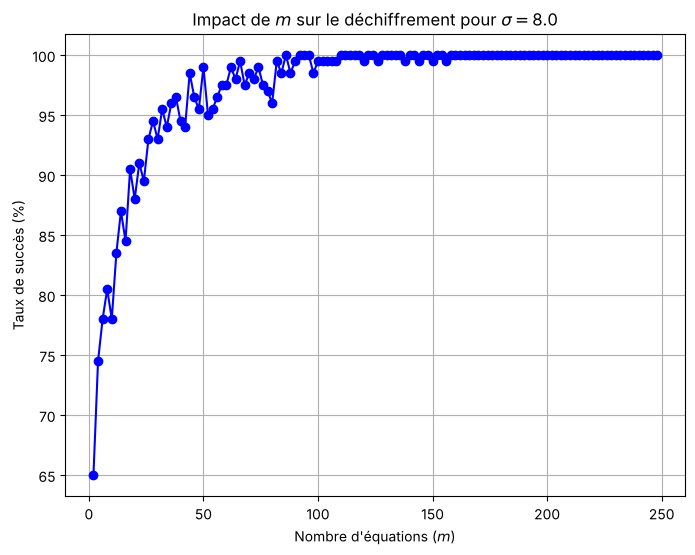

In [16]:
sigma = 8.0
n, q = 2, 11

liste_m = np.arange(2, 250, 2)
taux_globaux_m = []

#On boucle sur chaque m
for m in liste_m:
  success = 0

  for i in range(200):
      A = rng.integers(0, q, size=(m, n))
      s = rng.integers(0, q, size=n)

      msg = rng.integers(0, 2)

      b = chiffrer_LWE(msg, sigma, A, s, m, q)

      v, m_dechiffre = dechiffrer_LWE(b, A, s, q)

      if msg == m_dechiffre :
        success += 1
  taux = (success/200)*100
  taux_globaux_m.append(taux)

plt.figure(figsize=(8, 6))
plt.plot(liste_m, taux_globaux_m, color="blue", marker="o")
plt.xlabel(r"Nombre d'équations ($m$)")
plt.ylabel(r"Taux de succès (%)")
plt.title(r"Impact de $m$ sur le déchiffrement pour $\sigma =$" + f"{sigma}")
plt.grid(True)
plt.show()



###Résultats et interpretation
**Observation :**

La courbe montre une transition claire en fonction de $m$. Pour un faible nombre d'équations ($m < 20$), le taux de succès est nettement dégradé (entre 65 % et 90 %) et fluctue fortement.

À mesure que $m$ augmente, le taux de déchiffrement progresse. À partir de $m \approx 100$, les fluctuations s'estompent et le taux de succès se stabilise à 100 %.

**Interprétation mathématique :** Ce comportement valide empiriquement la Loi des Grands Nombres (LGN) appliquée au lissage du bruit.

Soit $\bar{D} = \frac{1}{m}\sum_{i=1}^{m} |v_i|$ la distance moyenne calculée au déchiffrement. Sa variance décroît en :

$$\text{Var}(\bar{D}) = \frac{\text{Var}(|v_i|)}{m}$$

Pour $m$ petit, l'échantillon est trop restreint : la moyenne fluctue fortement et franchit souvent le seuil de décision $q/4 = 2{,}75$, ce qui provoque des erreurs de décodage.

Lorsque $m$ grandit, la LGN assure la convergence :

$$\lim_{m \to \infty} \text{Var}(\bar{D}) = 0$$

Pour $m \ge 100$ avec $\sigma = 8$, la dispersion de la moyenne est suffisamment écrasée pour qu'elle reste toujours du bon côté du seuil.

Le système devient statistiquement robuste et garantit un déchiffrement parfait.

##4.4 Impact de n (la dimension du secret)

Dans cette section, nous allons étudier la taille de $n$, le $n$ est le **paramètre de sécurité** principal: plus $n$ est grand, plus le secret $s$ est long, et plus le système est difficile à attaquer pour un ordinateur (ou un ordinateur quantique).

Commençons par tester 2 valeurs de $n$, $n = 1$, $n = 250$:

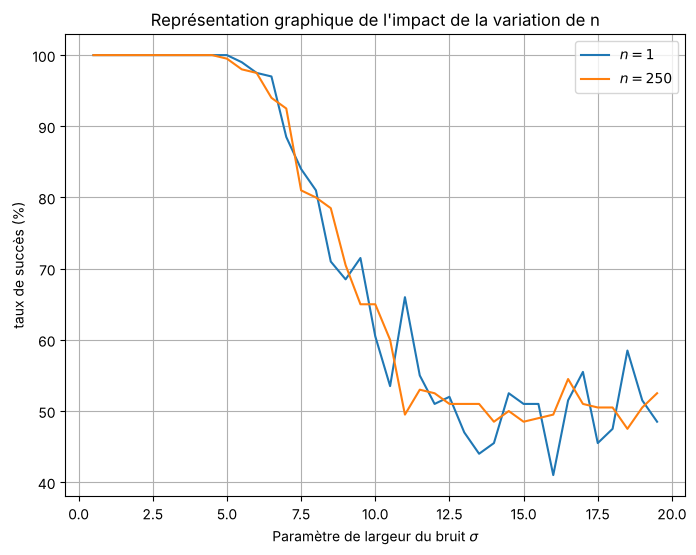

In [17]:
m, q = 10, 11
liste_n = [1, 250]
x = np.arange(0.5, 20.0, 0.5) #les valeurs de sigma

plt.figure(figsize=(8, 6))

for n in liste_n:
  plt.plot(x, etude_transition_phase(n, m, q, x), label=f"$n={n}$")

plt.legend()
plt.xlabel(r"Paramètre de largeur du bruit $\sigma$")
plt.ylabel(r"taux de succès (%)")
plt.grid(True)
plt.title("Représentation graphique de l'impact de la variation de n")
plt.show()




###Résultats et Interprétation

**Observation :**
Nous constatons graphiquement que les courbes pour $n = 1$ et $n = 250$ se superposent presque parfaitement. Contrairement à $m$, faire varier la dimension du secret $n$ de manière extrème n'altère pas la transition de phase de déchiffrement.

**Pourquoi ?**

Ce comportement s'explique par l'étude analytique du protocole. Lors de la phase de déchiffrement, l'utilisateur calcule pour chaque équation $i$ : $$v_i = b_i - A_i \cdot s \pmod q$$

En substituant la formule de chiffrement $b_i = A_i \cdot s + e_i + msg \cdot \lfloor q/2 \rfloor$,

nous obtenons : $$v_i = (A_i \cdot s + e_i + msg \cdot \lfloor q/2 \rfloor) - A_i \cdot s \equiv e_i + msg \cdot \lfloor q/2 \rfloor \pmod q$$

Cette égalité démontre que le signal reçu après correction ($v_i$) dépend exclusivement du message initial et du bruit isolé $e_i$. La dimension $n$ (le nombre de colonnes de $A$) et le secret $s$ s'annulent.

Comme le bruit $e_i \sim D_{\mathbb{Z},\sigma}$ est échantillonné indépendamment de $n$, la probabilité d'erreur de décodage par ligne est mathématiquement invariante selon $n$.

**Conclusion :** La dimension de $n$ n'a aucun impact sur la fiabilité du déchiffrement pour l'utilisateur légitime.
Son augmentation sert uniquement à garantir la sécurité du chiffrement en augmentant la complexité de la recherche du secret $s$ pour un attaquant.

###Complexité et Sécurité face à l'attaquant

**Le problème de l'attaquant : La recherche de cible**

L'attaquant intercepte le couple public  $(A, b) \in \mathbb{Z}_q^{m \times n} \times \mathbb{Z}_q^m$. Son but est de retrouver le secret unique $s \in \mathbb{Z}_q^n$. Il sait que:
$$b = A \cdot s + e \pmod q$$

S'il n'y avait pas de bruit ($e = 0$), l'attaquant résoudrait le système par un pivot de Gauss en complexité $\mathcal{O}(m \cdot n^2)$.

Cependant, à cause du bruit $e$, chaque ligne $i$ du système présente une petite erreur inconnue $e_i \in \{-\lfloor q/4 \rfloor, \dots, \lfloor q/4 \rfloor\}$. Tenter un pivot de Gauss classique va combiner et multiplier ces erreurs de manière linéaire, rendant le système d'équations faux.

**L'attaque par la Force Brute**

L'attaque par force brute consiste à tester tous les vecteurs candidats $s'$ possibles dans l'espace des clés.

- L'espace des secrets est l'ensemble vectoriel $\mathbb{Z}_q^n$.
- Le nombre de secrets possibles (le cardinal de l'espace) est donné par : $$\text{Nombre de clés possibles} = q^n$$

Pour chaque candidat $s'$, l'attaquant doit calculer le vecteur résiduel $e' = b - A \cdot s' \pmod q$. Si les composantes de $e'$ suivent une distribution gaussienne proche de 0, il a trouvé le bon secret.

La complexité algorithmique temporelle de cette recherche est de la forme : $$\mathcal{O}(n \cdot m \cdot q^n)$$

L'impact de la dimension $n$ est ici **exponentiel**. Par exemple :
- Avec $n = 2$ et $q = 11$, l'attaquant à $11^2 = 121$ opérations à faire.
- Avec $n = 250$ et $q = 11$, la complexité est de l'ordre $11^{250} \approx 10^{260}$ opérations. Ce nombre dépasse largement le nombre d'atomes dans l'univers observable ($\approx 10^{80}$).

Ainsi, l'attaque par la force brute n'est pas une méthode envisageable dès que $n$ prend des valeurs élevées.

**Remarque :** la force brute n'est pas la meilleure attaque. Les attaques par réduction de réseaux (LLL, BKZ) exploitent la petite taille du bruit et sont beaucoup plus efficaces : ce sont elles qui déterminent en pratique la sécurité de LWE (voir la section 2.2).

###Impact de q (modulo)

L'idée est de comprendre comment la taille de $q$ influence le déchiffrement.

**L'intuition mathématique:**

Le bruit $\sigma$ « grignote » l'espace du modulo $q$.

- Si $q$ est très petit (comme $q = 11$) et un bruit de $\sigma = 2$ est énorme car il représente une grande partie de l'espace disponible avant d'atteindre le seuil d'erreur ($\approx q/4$)

- Si $q$ est plus grand (par exemple $q = 101$), un bruit de $\sigma = 2$ devient minuscule et insignifiant par rapport à la taille du modulo.

On s'attend donc à ce qu'augmenter $q$ **rend le déchiffrement beaucoup plus robuste et tolérant à de plus grands bruits**.

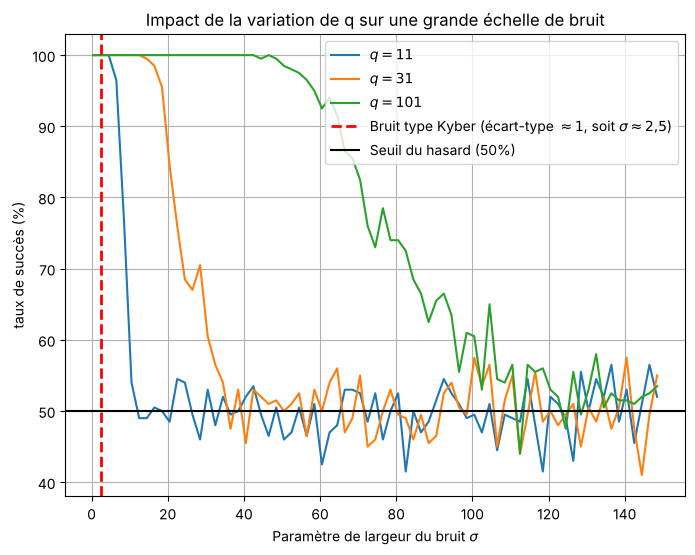

In [18]:
m, n = 10, 2
liste_q = [11, 31, 101]
x = np.arange(0.5, 150.0, 2.0) #les valeurs de sigma

plt.figure(figsize=(8, 6))

for q in liste_q:
  plt.plot(x, etude_transition_phase(n, m, q, x), label=f"$q={q}$")

plt.axvline(x=2.5, color='red', linestyle='--', linewidth=2, label=r'Bruit type Kyber (écart-type $\approx 1$, soit $\sigma \approx 2{,}5$)')
plt.axhline(y=50, color='black', label='Seuil du hasard (50%)')

plt.legend()
plt.xlabel(r"Paramètre de largeur du bruit $\sigma$")
plt.ylabel(r"taux de succès (%)")
plt.grid(True)
plt.title("Impact de la variation de q sur une grande échelle de bruit")
plt.show()

###Impact du modulo $q$ sur la tolérance au bruit

**Observation :**
Sur ce graphique à grande échelle, nous constatons que la taille du modulo $q$ dicte le niveau de bruit que le système peut tolérer.

- Pour $q = 11$, la courbe s'effondre presque immédiatement (vers $\sigma \approx 5$ à $10$).
- Pour $q = 31$, la chute a lieu vers $\sigma \approx 20$ à $30$.
- Pour $q = 101$, le taux de succès reste parfait jusqu'à $\sigma \approx 50$, puis chute progressivement pour atteindre 50 % vers $\sigma \approx 100$.

Plus le modulo $q$ est grand, plus la transition de phase est décalée vers la droite. On remarque même que la position de la transition est **à peu près proportionnelle à $q$** : le niveau du hasard est atteint vers $\sigma \approx 10$, $30$ et $100$, soit $\sigma \approx q$.

Cette divergence de comportement s'explique par la géométrie du décodage dans l'espace $\mathbb{Z}_q$. La tolérance maximale au bruit (le seuil de décision pour distinguer les deux messages) est proportionnelle à la taille du modulo : $$ \text{Seuil de tolérance} = q/4$$

Pour un $\sigma$ donné, le bruit injecté est statistiquement identique pour les trois configurations. Cependant :

- Pour $q = 11$, le seuil vaut $2{,}75$ : un bruit d'amplitude $3$ est déjà mal interprété.
- Pour $q = 31$, le seuil s'élève à $7{,}75$.
- Pour $q = 101$, le seuil atteint $25{,}25$. Une erreur de taille 10, fatale pour $q = 11$, est ici sans conséquence.

**Conclusion:**
Augmenter le modulo $q$ élargit les zones de décision lors du déchiffrement, ce qui garantit à l'utilisateur légitime une excellente fiabilité. Le paramètre qui compte vraiment est donc le **rapport** entre le bruit et le modulo.

###Analyse croisée et interaction ($m$ et $\sigma$)

Jusqu'à présent, nous avons étudié l'impact des paramètres $m$,$n$ et $q$ de manière totalement isolée en fixant arbitrairement les autres variables. Dans un scénario réel, ces paramètres coexistent et s'influencent mutuellement.

Le but de cette section est de réaliser une analyse croisée en deux dimensions pour observer comment le nombre d'équations disponibles ($m$) intéragit directement avec l'intensité du bruit ($\sigma$).

Pour ce faire, nous allons générer une Heatmap (carte de chaleur). Le principe est de cartographier le taux de succès du déchiffrement (représenté par un dégradé de couleur allant du rouge au vert) sur une grille ou chaque case correspond à un couple unique ($m, \sigma$).

**Comportement attendu (Hypothèse)**:
D'après les résultats obtenus précédemment, on s'attend à :

- L'augmentation de l'écart-type $\sigma$ injecte des perturbations plus fortes, ce qui tend à pousser le système vers l'échec (taux de succès à 50%).

- L'augmentation du nombre d'équations $m$ permet à la loi des grands nombres d'agir, ce qui tend à stabiliser le système (taux de succès à 100%).



In [19]:
import seaborn as sns

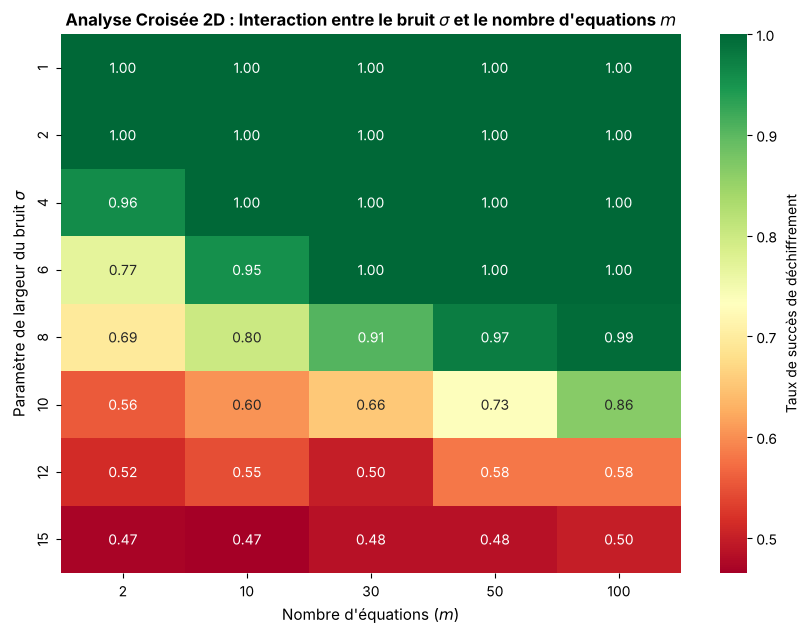

In [20]:
ms = [2, 10, 30, 50, 100]
sigmas = [1, 2, 4, 6, 8, 10, 12, 15]

n, q = 10, 11
nb_tests = 200

#on crée une matrice de 0 avec les bonnes dimensions
#les lignes = nb sigmas et colonnes = nb de m

matrice = np.zeros((len(sigmas), len(ms)))

#double boucle imbriquées

for i, sigma in enumerate(sigmas):
  for j, m in enumerate(ms):
    succes = 0
    for a in range(nb_tests):

      #Mini simulation de LWE
      msg = rng.integers(0, 2)
      A = rng.integers(0, q, size=(m, n))
      s = rng.integers(0, q, size=n)

      b = chiffrer_LWE(msg, sigma, A, s, m, q)

      _, msg_trouve = dechiffrer_LWE(b, A, s, q)

      if msg_trouve == msg:
        succes +=1
    matrice[i, j] = succes /nb_tests

#La Heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    matrice,
    annot = True,
    fmt=".2f",
    cmap="RdYlGn", #rouge vers le jaune vers le vert
    xticklabels=ms,
    yticklabels=sigmas,
    cbar_kws={'label': 'Taux de succès de déchiffrement'}
)

plt.title(r"Analyse Croisée 2D : Interaction entre le bruit $\sigma$ et le nombre d'equations $m$", fontsize=12, fontweight="bold")
plt.xlabel(r"Nombre d'équations ($m$)", fontsize=11)
plt.ylabel(r"Paramètre de largeur du bruit $\sigma$", fontsize=11)

plt.grid(False)
plt.show()




**Explications**

Ici, $n = 10$ et $q = 11$. Le seuil critique de tolérance aux erreurs est :

$$\text{Seuil} = q/4 = 2{,}75$$

Lors du déchiffrement, l'algorithme calcule la distance moyenne $\bar{D}$ des composantes recentrées à $0$, et applique la règle :

- $\text{Si } \bar{D} \le q/4 \implies \text{Message} = 0$
- $\text{Si } \bar{D} > q/4 \implies \text{Message} = 1$

**Zone verte ($\sigma \le 2$) :** le bruit est petit devant le seuil. Le déchiffrement est parfait quel que soit $m$.

**Zone de transition ($\sigma$ entre 4 et 10) :** c'est là que $m$ fait toute la différence. Par exemple, pour $\sigma = 8$, le taux de succès passe de $0{,}69$ avec $m = 2$ à $0{,}99$ avec $m = 100$. D'après la **loi des grands nombres**, la variance de la moyenne est divisée par $m$, ce qui stabilise la décision.

**Zone rouge ($\sigma \ge 12$) :** le bruit est devenu pratiquement uniforme sur $\mathbb{Z}_{11}$. Les deux messages produisent alors des distances moyennes de même loi : le taux reste autour de $0{,}50$, **même avec $m = 100$**. Il n'y a plus aucun signal à récupérer, l'algorithme devine au hasard.

**Conclusion :**

Augmenter le nombre d'équations ($m$) permet de lisser le bruit, mais la loi des grands nombres ne peut rien sauver si le bruit de départ $\sigma$ a déjà saturé le modulo $q$. Pour rester loin de la zone rouge, **Kyber** choisit un bruit très petit (écart-type de l'ordre de $1$) devant son modulo $q = 3329$.

#Partie 5: Bilan, Perspectives et Ouverture

##5.1 Comparaison RSA vs LWE

| Critère | RSA (Approche algébrique classique) | LWE (Approche géométrique post-quantique) |
| :--- | :--- | :--- |
| **Le problème mathématique** | **La factorisation dans l'anneau $\mathbb{Z}/n\mathbb{Z}$.**<br><br>La sécurité repose sur la difficulté calculatoire de retrouver deux grands facteurs premiers $p$ et $q$ à partir de leur produit $n = p \cdot q$.<br><br>C'est un problème unidimensionnel basé sur l'arithmétique modulaire. | **Le décodage de codes linéaires perturbés.**<br><br>Le secret est caché dans un espace vectoriel de grande dimension $n$.<br><br>On construit un système d'équations matricielles linéaires auquel on injecte un "bruit" aléatoire issu d'une distribution gaussienne discrète ($b = As + e$). |
| **Résistance face au calcul quantique** | **Vulnérabilité totale.**<br><br>L'algorithme de Shor utilise la Transformée de Fourier Quantique pour trouver la période de la fonction d'exponentiation modulaire en temps polynomial.<br><br>L'espace de recherche s'effondre. | **Résistance présumée.**<br><br>À ce jour, on ne connaît aucun algorithme quantique capable de résoudre efficacement le problème du plus court vecteur (SVP) ou de retrouver le point d'origine lorsque le système est perturbé par du bruit. |
| **Complexité computationnelle** | **Coûteuse en calculs (Asymptotique).**<br><br>Le chiffrement exige des opérations d'exponentiation modulaire sur des entiers de plusieurs milliers de bits.<br><br>Cela demande une puissance CPU importante pour la manipulation de ces grands nombres. | **Algorithme d'algèbre linéaire simple.**<br><br>Les opérations fondamentales se résument à des produits matrice-vecteur et des additions vectorielles dans $\mathbb{Z}/q\mathbb{Z}$.<br><br>Le coût de calcul est minimal pour les machines. |

##5.2 Ce que j'ai appris tout au long de ce Notebook

Ce projet m'a permis d'appréhender de manière concrète la transition vers la cryptographie post-quantique.
A travers l'implémentation et la manipulation des paramètres ($n, m, q, \sigma$), j'ai compris que la sécurité informatique de demain repose sur la maîtrise statistique et géométrique d'un bruit.

L'analyse de la transition de phase m'a permis de comprendre le choix derrière les paramètres, surtout leur impact sur la robustesse face à l'attaquant, et la fiabilité pour l'utilisateur légitime.

##5.3 Ouverture sur Kyber/ML-KEM

L'algorithme LWE standard que nous avons étudié présente un défaut majeur dans la pratique : la taille de la matrice publique $A \in {Z}_q^{m \times n}$ grandit de manière quadratique, ce qui s'avère trop lourd pour les architectures réseau réelles (mémoire, bande passante).

Pour pallier ce problème, le standard mondial **ML-KEM** (connu aussi sous le nom de Kyber), sélectionné par le NIST en 2022 pour remplacer RSA, utilise une variante appelée **Module-LWE (ML-LWE).**

Au lieu d'utiliser des nombres entiers dans la matrice A, Kyber utilise des **polynômes** au sein d'un anneau cyclotomique :

$$R_q = \mathbb{Z}_q[X]/(X^{256} + 1)$$

L'avantage algorithmique est qu'une matrice de polynômes permet de compacter de manière spectaculaire la taille des clés publiques.

Concernant le choix des paramètres, Kyber fixe un modulo $q = 3329$ : assez petit pour garder des clés compactes, mais très grand devant le bruit (tiré selon une loi binomiale centrée, d'écart-type de l'ordre de $1$). Il utilise la Transformée en Nombre Entier (NTT) pour multiplier les polynômes en un temps $\mathcal{O}(d \log d)$.

Et à propos de la gestion de l'erreur, tout comme notre simulation, Kyber possède un taux d'échec de déchiffrement théorique non nul, mais il est mathématiquement bridé pour être inférieur à $2^{-139}$ (soit un risque plus faible que de voir une météorite détruire la Terre au même instant).

# Références Bibliographiques

1. **Regev, O. (2005).** *On lattices, learning with errors, random linear codes, and cryptography.* Journal of the ACM (JACM), 56(6), 1-40. (L'article fondateur qui a introduit le problème LWE et sa réduction de sécurité).
2. **Laguillaumie, F., Langlois, A., & Stehlé, D. (2014).** *Chiffrement avancé à partir du problème Learning With Errors.* HAL open science. [En ligne] https://inria.hal.science/hal-00984055v1/document (Une excellente ressource de référence en français détaillant les constructions avancées autour de LWE).
3. **Shor, P. W. (1994).** *Algorithms for quantum computation: discrete logarithms and factoring.* IEEE. (La démonstration historique de la vulnérabilité de RSA et du logarithme discret face au calcul quantique).
4. **Micciancio, D. (2020).** *The Learning With Errors Problem (LWE).* UC San Diego (CSE 208). [Slides de cours] https://cseweb.ucsd.edu/classes/fa20/cse208-a/lwe.pdf (Support de cours universitaire très clair résolvant les aspects géométriques et algorithmiques de LWE).
5. **NIST (2024).** *FIPS 203: Module-Lattice-Based Key-Encapsulation Mechanism Standard.* (Le document officiel fixant les spécifications industrielles mondiales de ML-KEM / Kyber).
6. **Contributeurs de Wikipédia (2024).** *Apprentissage avec erreurs.* Wikipédia, l'encyclopédie libre. [En ligne] https://fr.wikipedia.org/wiki/Apprentissage_avec_erreurs (Une base de vulgarisation rigoureuse et accessible en français).
7. **Roetteler, M., Naehrig, M., Svore, K. M., & Vasudevan, C. (2017).** *Quantum resource estimates for computing elliptic curve discrete logarithms.* (Évaluation et quantification des ressources quantiques nécessaires pour la transition cryptographique).